# Project 12: E. coli Protein Data Exploratory Data Analysis (EDA)
**Student Name:** RAJNISH KUMAR YADAV  
**Roll Number:** 2026B01010428  
**Class / Section:** CSE11  
**Course:** B.Tech  
**Faculty / Guide:** Faizan Sir  
**Submission Date:** 21 November 2026  
**Dataset Source:** [UCI Machine Learning Repository — Ecoli Dataset](https://archive.ics.uci.edu/dataset/39/ecoli)  
**Tools Used:** Python, NumPy, Pandas, Matplotlib  

---

## 1. Import Required Libraries & Load Dataset
The `ecoli.data` file has 336 rows and 9 space-separated columns without a header row. Based on the UCI dataset documentation (`ecoli.names`), we assign clear column names upon loading.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Column names from UCI E. coli dataset documentation
column_names = [
    'Sequence_Name',  # Accession number for the SWISS-PROT database
    'mcg',            # McGeoch's method for signal sequence recognition
    'gvh',            # von Heijne's method for signal sequence recognition
    'lip',            # von Heijne's Signal Peptidase II consensus sequence score
    'chg',            # Presence of charge on N-terminus of predicted lipoproteins
    'aac',            # Score of discriminant analysis of the amino acid content
    'alm1',           # Score of the ALOM membrane spanning region prediction program
    'alm2',           # Score of ALOM program after excluding putative cleavable signal regions
    'Class'           # Protein localization site (target class)
]

# Direct URL to UCI E. coli data file
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/ecoli/ecoli.data"

# Load dataset (or upload ecoli.data to Colab and pass 'ecoli.data' if offline)
df = pd.read_csv(url, sep=r'\s+', names=column_names)
print("Dataset loaded successfully!")

Dataset loaded successfully!


## 2. Inspect Dataset Structure (`head`, `tail`, `shape`, `info`, `describe`)

In [2]:
print("--- First 5 Rows (head) ---")
display(df.head())

print("\n--- Last 5 Rows (tail) ---")
display(df.tail())

print(f"\n--- Dataset Shape ---\nRows: {df.shape[0]}, Columns: {df.shape[1]}")

print("\n--- Dataset Info ---")
df.info()

print("\n--- Statistical Summary (describe) ---")
display(df.describe())

--- First 5 Rows (head) ---


,Sequence_Name,mcg,gvh,lip,chg,aac,alm1,alm2,Class
0,AAT_ECOLI,0.49,0.29,0.48,0.5,0.56,0.24,0.35,cp
1,ACEA_ECOLI,0.07,0.40,0.48,0.5,0.54,0.35,0.44,cp
2,ACEK_ECOLI,0.56,0.40,0.48,0.5,0.49,0.37,0.46,cp
3,ACKA_ECOLI,0.59,0.49,0.48,0.5,0.52,0.45,0.36,cp
4,ADI_ECOLI,0.23,0.32,0.48,0.5,0.55,0.25,0.35,cp



--- Last 5 Rows (tail) ---


,Sequence_Name,mcg,gvh,lip,chg,aac,alm1,alm2,Class
331,TREA_ECOLI,0.74,0.56,0.48,0.5,0.47,0.68,0.30,pp
332,UGPB_ECOLI,0.71,0.57,0.48,0.5,0.48,0.35,0.32,pp
333,USHA_ECOLI,0.61,0.60,0.48,0.5,0.44,0.39,0.38,pp
334,XYLF_ECOLI,0.59,0.61,0.48,0.5,0.42,0.42,0.37,pp
335,YTFQ_ECOLI,0.74,0.74,0.48,0.5,0.31,0.53,0.52,pp



--- Dataset Shape ---
Rows: 336, Columns: 9

--- Dataset Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 336 entries, 0 to 335
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Sequence_Name  336 non-null    object 
 1   mcg            336 non-null    float64
 2   gvh            336 non-null    float64
 3   lip            336 non-null    float64
 4   chg            336 non-null    float64
 5   aac            336 non-null    float64
 6   alm1           336 non-null    float64
 7   alm2           336 non-null    float64
 8   Class          336 non-null    object 
dtypes: float64(7), object(2)
memory usage: 23.8+ KB

--- Statistical Summary (describe) ---


,mcg,gvh,lip,chg,aac,alm1,alm2
count,336.000000,336.000000,336.000000,336.000000,336.000000,336.000000,336.000000
mean,0.500060,0.500000,0.495476,0.501488,0.500030,0.500179,0.499732
std,0.194634,0.148157,0.088495,0.027277,0.122376,0.215751,0.209411
min,0.000000,0.160000,0.480000,0.500000,0.000000,0.030000,0.000000
25%,0.340000,0.400000,0.480000,0.500000,0.420000,0.330000,0.350000
50%,0.500000,0.470000,0.480000,0.500000,0.495000,0.455000,0.430000
75%,0.662500,0.570000,0.480000,0.500000,0.570000,0.710000,0.710000
max,0.890000,1.000000,1.000000,1.000000,0.880000,1.000000,0.990000


## 3. Data Quality Check: Missing Values & Duplicates (Analysis Question 6)

In [3]:
print("--- Missing Values per Column ---")
missing_values = df.isnull().sum()
print(missing_values)
print(f"Total missing values: {missing_values.sum()}")

duplicate_count = df.duplicated().sum()
print(f"\n--- Duplicate Records ---\nTotal duplicate rows: {duplicate_count}")

if duplicate_count > 0:
    df = df.drop_duplicates()
    print("Duplicates removed.")
else:
    print("No duplicate rows found. Dataset is clean.")

--- Missing Values per Column ---
Sequence_Name    0
mcg              0
gvh              0
lip              0
chg              0
aac              0
alm1             0
alm2             0
Class            0
dtype: int64
Total missing values: 0

--- Duplicate Records ---
Total duplicate rows: 0
No duplicate rows found. Dataset is clean.


## 4. Analysis Questions 1 & 3: Record Counts per Localization Class & Largest Class

In [4]:
# Question 1: Count records in each localization class
class_counts = df['Class'].value_counts()
print("--- Record Count per Localization Class ---")
print(class_counts)

# Question 3: Which class has the most records?
top_class = class_counts.idxmax()
top_count = class_counts.max()
print(f"\nLocalization class with the most records: '{top_class}' ({top_count} records, {top_count/len(df)*100:.2f}% of dataset)")

--- Record Count per Localization Class ---
Class
cp     143
im      77
pp      52
imU     35
om      20
omL      5
imL      2
imS      2
Name: count, dtype: int64

Localization class with the most records: 'cp' (143 records, 42.56% of dataset)


## 5. Analysis Question 2: NumPy Statistics (Mean, Median, Min, Max) for Numeric Columns

In [5]:
# Calculate mean, median, minimum, and maximum using NumPy arrays for 3 numeric columns
selected_cols = ['mcg', 'gvh', 'alm1']
numpy_stats = []

for col in selected_cols:
    arr = df[col].to_numpy()  # Convert Pandas Series to NumPy array
    numpy_stats.append({
        'Column': col,
        'Mean': round(float(np.mean(arr)), 4),
        'Median': round(float(np.median(arr)), 4),
        'Minimum': round(float(np.min(arr)), 4),
        'Maximum': round(float(np.max(arr)), 4)
    })

stats_df = pd.DataFrame(numpy_stats)
print("--- NumPy Summary Statistics for Selected Columns ---")
display(stats_df)

--- NumPy Summary Statistics for Selected Columns ---


,Column,Mean,Median,Minimum,Maximum
0,mcg,0.5001,0.500,0.00,0.89
1,gvh,0.5000,0.470,0.16,1.00
2,alm1,0.5002,0.455,0.03,1.00


## 6. Analysis Question 4: Compare Average Values of Two Numeric Columns Across Classes

In [6]:
# Compare average values of 'mcg' and 'gvh' across localization classes using groupby()
class_comparison = df.groupby('Class')[['mcg', 'gvh']].mean().round(4)
class_comparison = class_comparison.sort_values(by='mcg', ascending=False)

print("--- Mean 'mcg' and 'gvh' Scores by Localization Class ---")
display(class_comparison)

--- Mean 'mcg' and 'gvh' Scores by Localization Class ---


,mcg,gvh
Class,,
imS,0.7400,0.5100
imU,0.7260,0.4589
imL,0.7250,0.4700
omL,0.6980,0.5120
om,0.6725,0.7100
pp,0.6521,0.6998
im,0.4784,0.4966
cp,0.3636,0.4097


## 7. Analysis Question 5: Find Records with Highest Values in a Selected Column

In [7]:
# Sort and filter records with the highest values in 'mcg'
top_mcg_records = df.sort_values(by='mcg', ascending=False)[['Sequence_Name', 'mcg', 'gvh', 'alm1', 'Class']].head(10)
print("--- Top 10 Protein Sequences with Highest 'mcg' Score ---")
display(top_mcg_records)

# Filtering example: records with mcg >= 0.85
high_mcg_filter = df[df['mcg'] >= 0.85][['Sequence_Name', 'mcg', 'Class']]
print(f"\n--- Filtered Records with mcg >= 0.85 ({len(high_mcg_filter)} records) ---")
display(high_mcg_filter)

--- Top 10 Protein Sequences with Highest 'mcg' Score ---


,Sequence_Name,mcg,gvh,alm1,Class
186,NHAA_ECOLI,0.89,0.55,0.72,im
252,SECD_ECOLI,0.88,0.42,0.73,imU
244,MCP4_ECOLI,0.87,0.49,0.76,imU
242,MCP1_ECOLI,0.86,0.39,0.89,imU
255,TYRP_ECOLI,0.86,0.55,0.81,imU
220,ATKC_ECOLI,0.85,0.53,0.52,imS
253,SECG_ECOLI,0.84,0.54,0.92,imU
157,DHG_ECOLI,0.84,0.44,0.71,im
236,FEPD_ECOLI,0.84,0.49,0.78,imU
226,CADB_ECOLI,0.83,0.48,0.76,imU



--- Filtered Records with mcg >= 0.85 (6 records) ---


,Sequence_Name,mcg,Class
186,NHAA_ECOLI,0.89,im
220,ATKC_ECOLI,0.85,imS
242,MCP1_ECOLI,0.86,imU
244,MCP4_ECOLI,0.87,imU
252,SECD_ECOLI,0.88,imU
255,TYRP_ECOLI,0.86,imU


## 8. Data Visualizations (2 Simple Charts)
1. **Bar Chart:** Record count per protein localization class.
2. **Histogram:** Distribution of `mcg` (McGeoch's signal sequence recognition score).

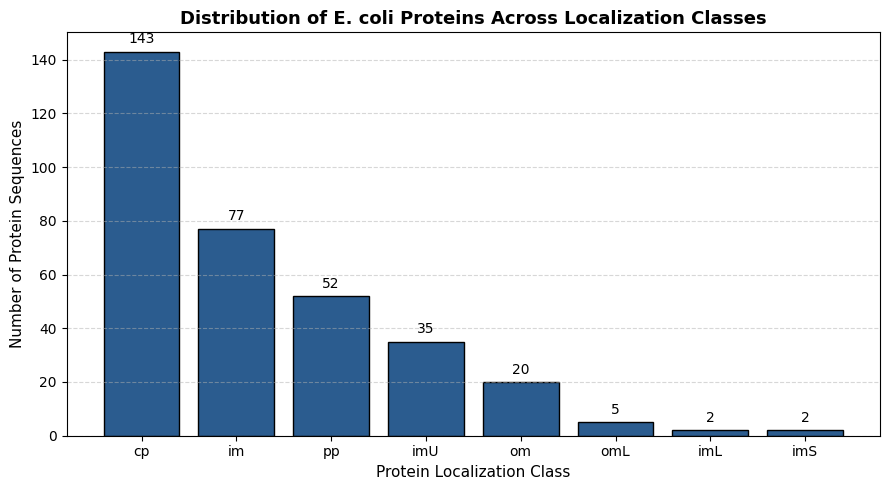

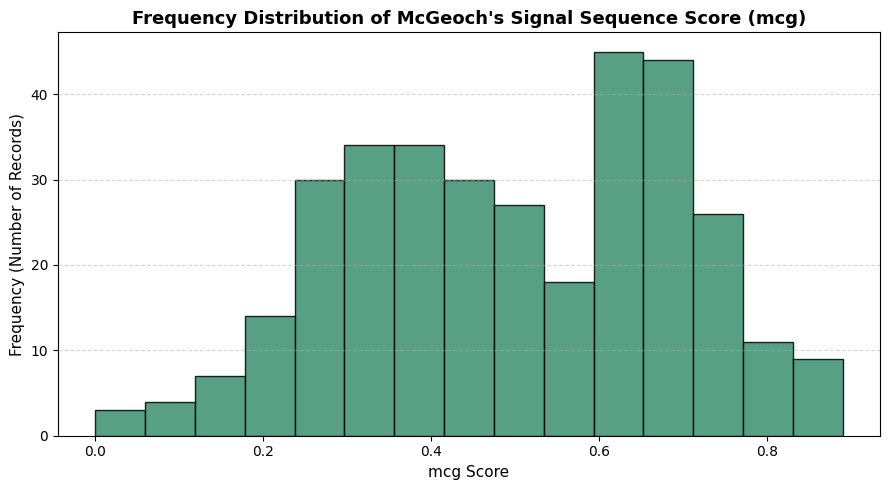

In [8]:
# Chart 1: Bar Chart of Localization Class Counts
plt.figure(figsize=(9, 5))
bars = plt.bar(class_counts.index, class_counts.values, color='#2b5c8f', edgecolor='black')
plt.title('Distribution of E. coli Proteins Across Localization Classes', fontsize=13, fontweight='bold')
plt.xlabel('Protein Localization Class', fontsize=11)
plt.ylabel('Number of Protein Sequences', fontsize=11)
plt.grid(axis='y', linestyle='--', alpha=0.5)

# Add value labels on top of bars
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + 2, int(yval), ha='center', va='bottom', fontsize=10)

plt.tight_layout()
plt.show()

# Chart 2: Histogram of 'mcg' Scores
plt.figure(figsize=(9, 5))
plt.hist(df['mcg'], bins=15, color='#3a8f6e', edgecolor='black', alpha=0.85)
plt.title("Frequency Distribution of McGeoch's Signal Sequence Score (mcg)", fontsize=13, fontweight='bold')
plt.xlabel('mcg Score', fontsize=11)
plt.ylabel('Frequency (Number of Records)', fontsize=11)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

## 9. Key Observations
1. **Class Imbalance & Dominant Localization Site:** Out of 336 *E. coli* protein sequences, the cytoplasmic class (`cp`) contains the highest number of records (143 sequences, ~42.56%), followed by inner membrane without signal sequence (`im`, 77 sequences) and periplasmic (`pp`, 52 sequences), while rare classes like `omL` (5), `imS` (2), and `imL` (2) represent less than 3% combined.
2. **Clean & Complete Dataset:** The dataset has zero missing values (`NaN`) and zero duplicate rows across all 336 records and 9 attributes, requiring no imputation or row deletion prior to exploratory analysis.
3. **Signal Sequence Score Variations Across Classes:** Outer membrane (`om`) and periplasmic (`pp`) proteins exhibit substantially higher average `mcg` and `gvh` signal-sequence recognition scores than cytoplasmic (`cp`) proteins, reflecting the biological presence of cleavable signal peptides in exported/membrane-bound proteins.